
# STRATUM — Equipment, Lot and Temporal Analysis

## Phase 2 — Step 2.4

### Objective

Investigate variation in semiconductor manufacturing
measurements across equipment, machines, production
lots and processing time.

### Research Questions

1. Do material properties vary across equipment?
2. Are machine-level differences observable?
3. How many wafers are associated with each lot?
4. Are different equipment used within the same lot?
5. How do thickness and sheet resistance change over time?
6. Are there signs of temporal shifts or process drift?
7. How should these findings influence model evaluation?

### Important Methodological Notes

- This notebook performs exploratory analysis only.
- Observed differences do not establish physical root causes.
- The original Infineon dataset remains unchanged.
- Exact equipment identities are anonymised.
- Chronological and lot-aware train-test splits will
  be considered during ML dataset preparation.

In [1]:

# STEP 2.4.2 - Load Infineon AlCu dataset

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

filename = "apc_spc_AlCu_inputs_outputs.csv"

current_dir = Path.cwd()

csv_path = current_dir / "data" / "raw" / filename

if not csv_path.exists():
    csv_path = current_dir.parent / "data" / "raw" / filename

if not csv_path.exists():
    raise FileNotFoundError(
        "Infineon dataset not found in data/raw."
    )

df = pd.read_csv(
    csv_path,
    sep=";",
    skiprows=1,
    low_memory=False
)

# Work on an in-memory analysis copy
analysis_df = df.copy()

# Parse timestamps without modifying the raw CSV
time_cols = [
    "batchstart", "batchend",
    "runstart", "runend"
]

for col in time_cols:
    analysis_df[col] = pd.to_datetime(
        analysis_df[col],
        errors="coerce"
    )

print("Dataset shape:", analysis_df.shape)
print("Invalid runstart values:",
      analysis_df["runstart"].isna().sum())

print("Earliest run:",
      analysis_df["runstart"].min())

print("Latest run:",
      analysis_df["runstart"].max())


Dataset shape: (5208, 178)
Invalid runstart values: 0
Earliest run: 2021-07-31 06:51:54
Latest run: 2025-05-31 17:04:14



## 1. Equipment Distribution

Examine the number of wafer records associated with
each anonymised equipment identifier.

Unequal equipment representation may influence
aggregate statistics and model evaluation.

,Wafer Count
equipment,
equipment_1,423
equipment_10,190
equipment_11,315
equipment_12,261
equipment_13,431
equipment_14,440
equipment_15,400
equipment_16,264
equipment_2,420


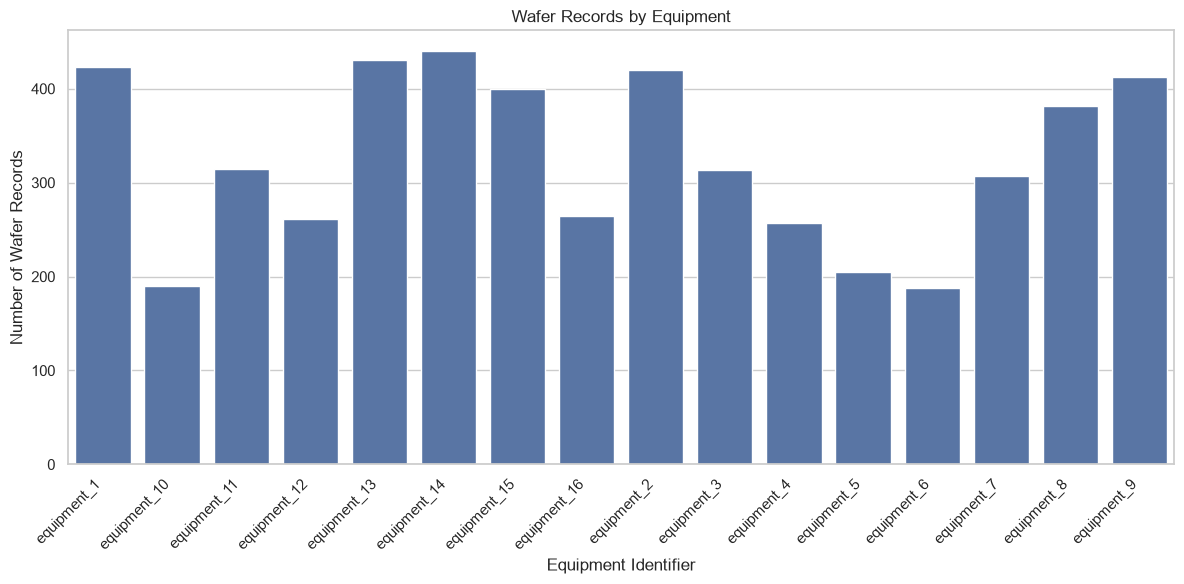

In [2]:

# STEP 2.4.3 - Equipment distribution

equipment_counts = (
    analysis_df["equipment"]
    .value_counts()
    .sort_index()
)

display(
    equipment_counts.to_frame("Wafer Count")
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=equipment_counts.index,
    y=equipment_counts.values
)

plt.title("Wafer Records by Equipment")
plt.xlabel("Equipment Identifier")
plt.ylabel("Number of Wafer Records")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()


## 2. Equipment-Level Thickness Variation

Compare mean AlCu film thickness across equipment.

Investigate differences in central tendency,
measurement spread and possible outliers.

Equipment-level association does not establish
that equipment identity causes the differences.

In [3]:

# STEP 2.4.4 - Thickness statistics by equipment

equipment_thickness = (
    analysis_df
    .groupby("equipment")["mean_thickness"]
    .agg(
        wafer_count="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
    .sort_values("mean")
)

display(equipment_thickness.round(4))

,wafer_count,mean,median,std,minimum,maximum
equipment,,,,,,
equipment_12,261,150.0935,149.3086,2.2711,145.6426,157.1051
equipment_4,257,151.1989,150.9446,2.1999,146.2347,157.0142
equipment_8,382,151.6079,151.5174,2.6981,142.0044,158.6250
equipment_16,264,151.6660,151.4962,2.4408,145.3159,157.7935
equipment_13,431,151.8587,152.1567,2.2436,145.5958,157.8250
equipment_6,188,152.0134,151.6595,2.3127,144.3836,163.6418
equipment_15,400,152.0732,152.1905,2.6575,144.8291,159.3845
equipment_9,412,152.0946,152.0042,1.6837,146.9717,157.7809
equipment_5,205,152.1006,152.2089,2.2729,146.6747,162.2830


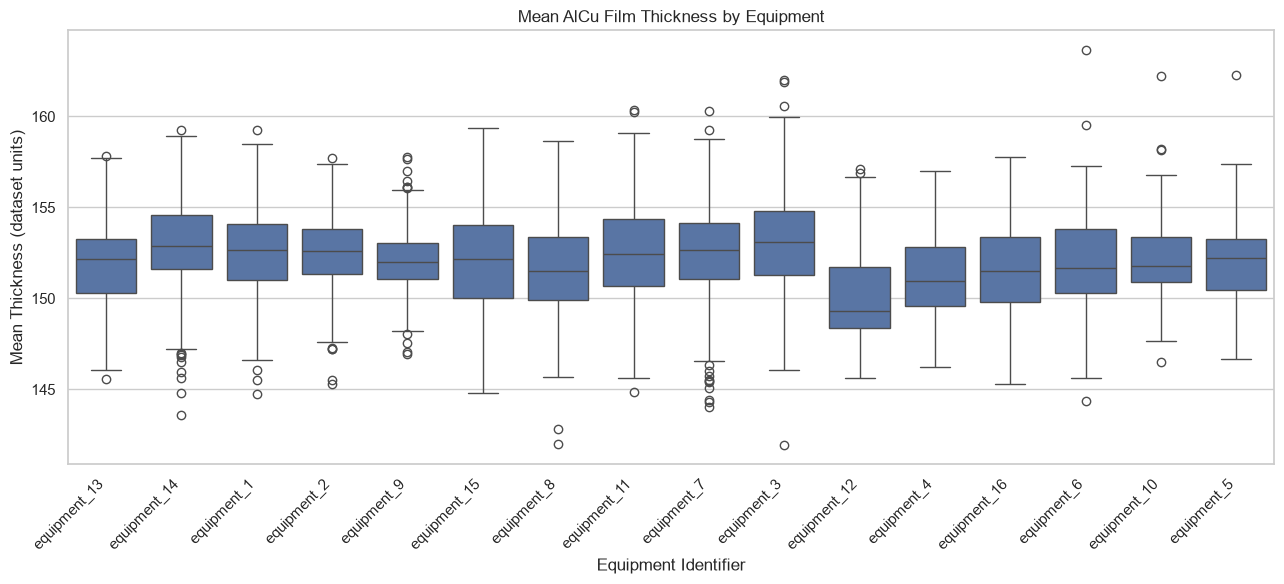

In [4]:

# Thickness distribution across equipment

plt.figure(figsize=(13, 6))

sns.boxplot(
    data=analysis_df,
    x="equipment",
    y="mean_thickness"
)

plt.title("Mean AlCu Film Thickness by Equipment")
plt.xlabel("Equipment Identifier")
plt.ylabel("Mean Thickness (dataset units)")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()


## 3. Equipment-Level Sheet Resistance Variation

Compare wafer-level mean sheet resistance across
different equipment identifiers.

Investigate whether electrical-property distributions
differ across manufacturing equipment.

,wafer_count,mean,median,std
equipment,,,,
equipment_3,313,0.002878,0.002877,0.000056
equipment_14,440,0.002884,0.002878,0.000049
equipment_1,423,0.002888,0.002881,0.000045
equipment_7,307,0.002890,0.002883,0.000055
equipment_2,420,0.002891,0.002889,0.000040
equipment_11,315,0.002891,0.002890,0.000056
equipment_9,412,0.002894,0.002894,0.000034
equipment_13,431,0.002900,0.002893,0.000047
equipment_15,400,0.002900,0.002895,0.000056


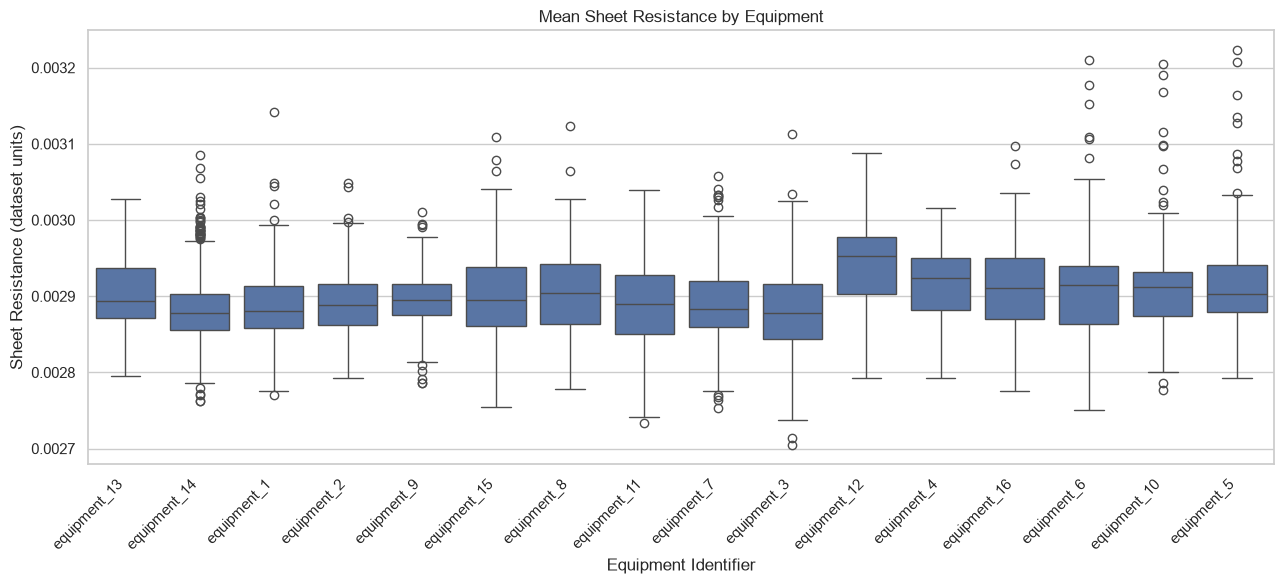

In [5]:

# STEP 2.4.5 - Resistance by equipment

equipment_resistance = (
    analysis_df
    .groupby("equipment")["mean_resistance"]
    .agg(
        wafer_count="count",
        mean="mean",
        median="median",
        std="std"
    )
    .sort_values("mean")
)

display(equipment_resistance.round(7))

plt.figure(figsize=(13, 6))

sns.boxplot(
    data=analysis_df,
    x="equipment",
    y="mean_resistance"
)

plt.title("Mean Sheet Resistance by Equipment")
plt.xlabel("Equipment Identifier")
plt.ylabel("Sheet Resistance (dataset units)")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()


## 4. Machine and Equipment Relationships

Examine the distribution of wafer records across
machine groups and equipment identifiers.

Compare mean thickness and sheet resistance
at the machine level.

machine,machine_1,machine_2,machine_3,machine_4,machine_5,machine_6
equipment,,,,,,
equipment_1,0,0,0,423,0,0
equipment_10,0,0,0,0,0,190
equipment_11,315,0,0,0,0,0
equipment_12,0,0,0,0,261,0
equipment_13,0,0,0,431,0,0
equipment_14,0,0,0,440,0,0
equipment_15,0,400,0,0,0,0
equipment_16,0,0,0,0,264,0
equipment_2,0,0,420,0,0,0


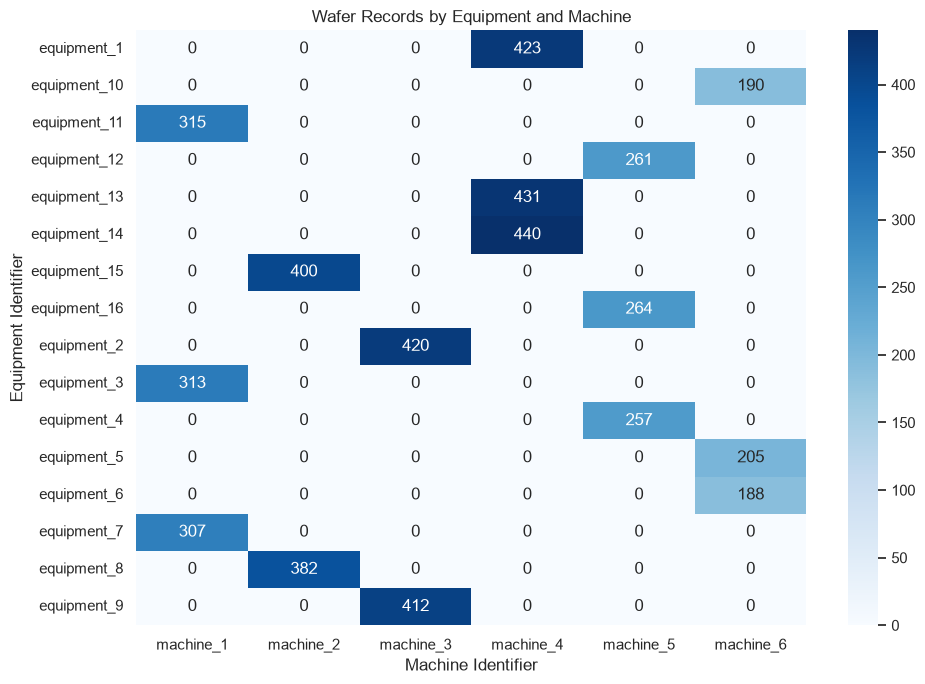

In [6]:

# STEP 2.4.6 - Machine and equipment cross-tabulation

equipment_machine_table = pd.crosstab(
    analysis_df["equipment"],
    analysis_df["machine"]
)

display(equipment_machine_table)

plt.figure(figsize=(10, 7))

sns.heatmap(
    equipment_machine_table,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Wafer Records by Equipment and Machine")
plt.xlabel("Machine Identifier")
plt.ylabel("Equipment Identifier")

plt.tight_layout()
plt.show()

In [7]:

machine_summary = (
    analysis_df
    .groupby("machine")
    .agg(
        wafer_count=("wafer_id", "count"),
        mean_thickness=("mean_thickness", "mean"),
        std_thickness=("mean_thickness", "std"),
        mean_resistance=("mean_resistance", "mean"),
        std_resistance=("mean_resistance", "std")
    )
)

display(machine_summary.round(7))

,wafer_count,mean_thickness,std_thickness,mean_resistance,std_resistance
machine,,,,,
machine_1,935,152.691405,2.830389,0.002887,0.000056
machine_2,782,151.845900,2.685789,0.002903,0.000056
machine_3,832,152.298284,1.869733,0.002893,0.000037
machine_4,1294,152.358562,2.389048,0.002891,0.000047
machine_5,782,150.987659,2.397306,0.002923,0.000050
machine_6,583,152.074772,2.197527,0.002913,0.000063



## 5. Production Lot Analysis

Analyse the number of wafer records per lot,
equipment diversity within lots, and variations
in material properties.

Lot information will help us assess the risk
of data leakage during model evaluation.

In [8]:

# STEP 2.4.7 - Lot-level summary

lot_summary = (
    analysis_df
    .groupby("lot")
    .agg(
        wafer_count=("wafer_id", "count"),
        equipment_count=("equipment", "nunique"),
        machine_count=("machine", "nunique"),
        mean_thickness=("mean_thickness", "mean"),
        thickness_std=("mean_thickness", "std"),
        mean_resistance=("mean_resistance", "mean"),
        first_run=("runstart", "min"),
        last_run=("runstart", "max")
    )
)

print("Number of unique lots:", len(lot_summary))

print("\nWafer count per lot:")
display(lot_summary["wafer_count"].describe())

print("\nLots using multiple equipment identifiers:")
print(
    (lot_summary["equipment_count"] > 1).sum()
)

print("\nLot size distribution:")
display(
    lot_summary["wafer_count"]
    .value_counts()
    .sort_index()
)

Number of unique lots: 2951

Wafer count per lot:


count    2951.000000
mean        1.764825
std         0.798471
min         1.000000
25%         1.000000
50%         2.000000
75%         2.000000
max         3.000000
Name: wafer_count, dtype: float64


Lots using multiple equipment identifiers:
1582

Lot size distribution:


wafer_count
1    1369
2     907
3     675
Name: count, dtype: int64

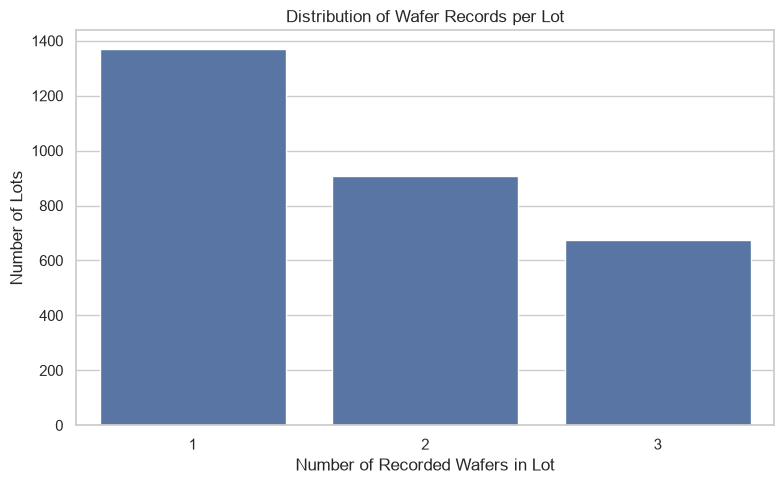

In [9]:

# Plot wafer records per lot

lot_counts = (
    lot_summary["wafer_count"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=lot_counts.index.astype(str),
    y=lot_counts.values
)

plt.title("Distribution of Wafer Records per Lot")
plt.xlabel("Number of Recorded Wafers in Lot")
plt.ylabel("Number of Lots")

plt.tight_layout()
plt.show()


## 6. Manufacturing Activity Over Time

Analyse the number of recorded wafers over time.

Determine whether historical records are
uniformly distributed across the observation period.

Record availability does not necessarily represent
the complete factory production volume.

,Wafer Records
run_month,
2024-06-01,109
2024-07-01,88
2024-08-01,99
2024-09-01,111
2024-10-01,119
2024-11-01,113
2024-12-01,98
2025-01-01,80
2025-02-01,106


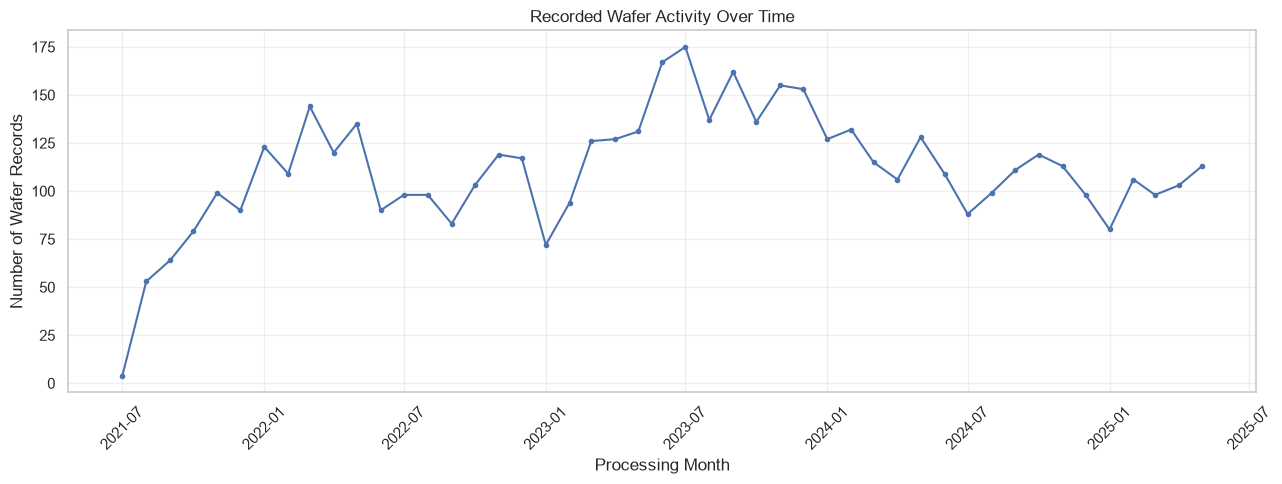

In [10]:

# STEP 2.4.8 - Monthly record counts

analysis_df["run_month"] = (
    analysis_df["runstart"].dt.to_period("M")
)

monthly_counts = (
    analysis_df
    .groupby("run_month")
    .size()
    .sort_index()
)

monthly_counts.index = (
    monthly_counts.index.to_timestamp()
)

display(
    monthly_counts.to_frame("Wafer Records").tail(12)
)

plt.figure(figsize=(13, 5))

plt.plot(
    monthly_counts.index,
    monthly_counts.values,
    marker="o",
    markersize=3
)

plt.title("Recorded Wafer Activity Over Time")
plt.xlabel("Processing Month")
plt.ylabel("Number of Wafer Records")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 7. Temporal Material-Property Trends

Investigate monthly changes in mean thickness
and mean sheet resistance.

Interpret apparent trends alongside the number
of observations and equipment representation.

Temporal associations do not independently
establish process drift or its root cause.

In [11]:

# STEP 2.4.9 - Monthly material-property statistics

monthly_properties = (
    analysis_df
    .groupby("run_month")
    .agg(
        wafer_count=("wafer_id", "count"),
        mean_thickness=("mean_thickness", "mean"),
        std_thickness=("mean_thickness", "std"),
        mean_resistance=("mean_resistance", "mean"),
        std_resistance=("mean_resistance", "std")
    )
)

monthly_properties.index = (
    monthly_properties.index.to_timestamp()
)

display(monthly_properties.tail(12).round(7))

,wafer_count,mean_thickness,std_thickness,mean_resistance,std_resistance
run_month,,,,,
2024-06-01,109,151.328697,2.469571,0.002918,0.000059
2024-07-01,88,150.953047,2.378668,0.002923,0.000047
2024-08-01,99,151.313721,2.886101,0.002912,0.000058
2024-09-01,111,152.631699,2.466778,0.002886,0.000050
2024-10-01,119,151.815322,2.593379,0.002906,0.000054
2024-11-01,113,151.657729,2.633682,0.002910,0.000053
2024-12-01,98,151.419173,2.021183,0.002913,0.000041
2025-01-01,80,151.446830,2.065699,0.002910,0.000040
2025-02-01,106,151.500433,2.364953,0.002908,0.000052


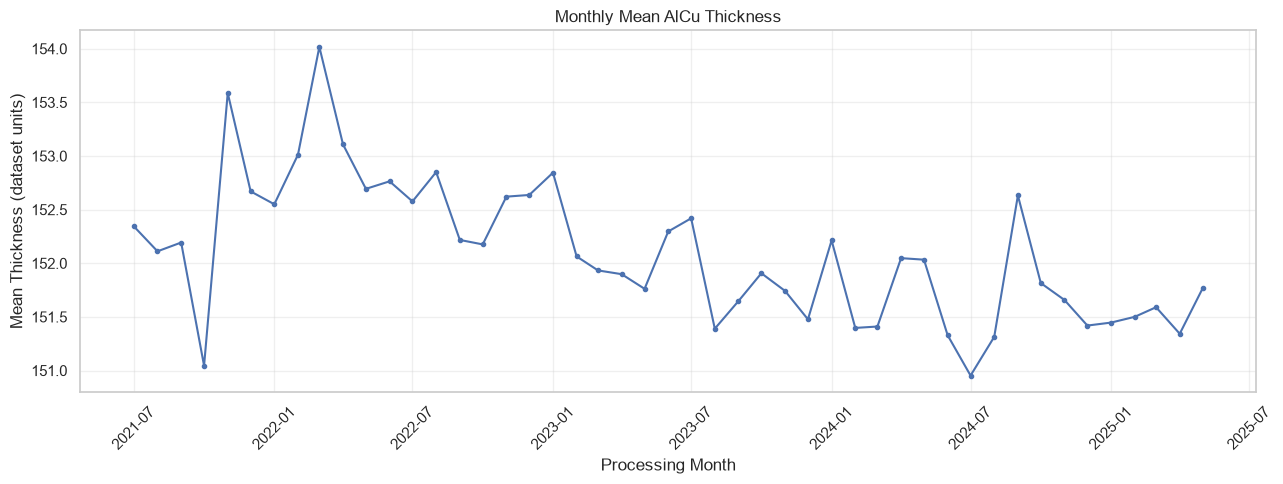

In [12]:

plt.figure(figsize=(13, 5))

plt.plot(
    monthly_properties.index,
    monthly_properties["mean_thickness"],
    marker="o",
    markersize=3
)

plt.title("Monthly Mean AlCu Thickness")
plt.xlabel("Processing Month")
plt.ylabel("Mean Thickness (dataset units)")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

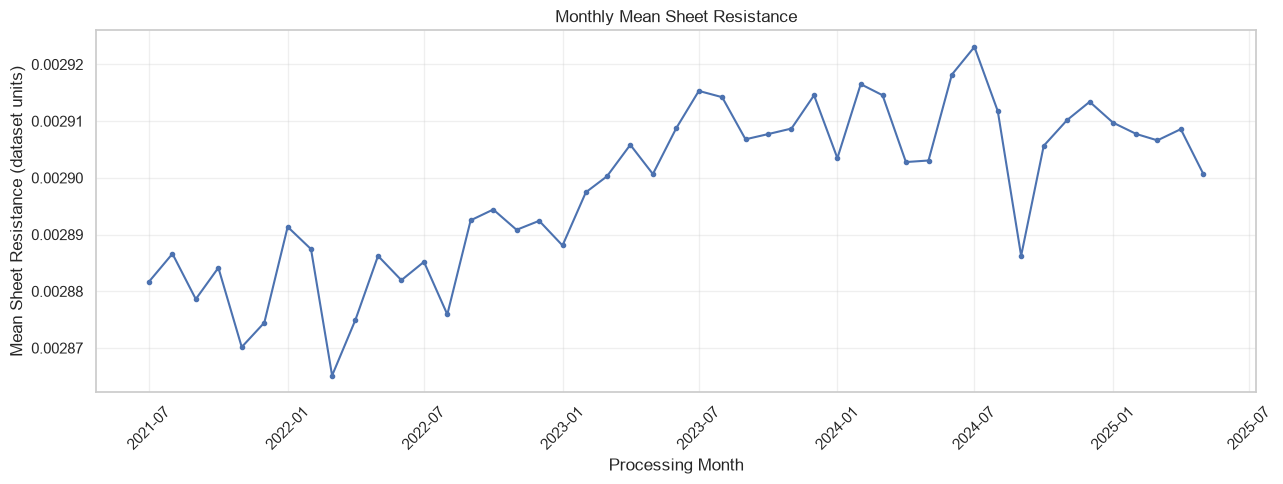

In [13]:

plt.figure(figsize=(13, 5))

plt.plot(
    monthly_properties.index,
    monthly_properties["mean_resistance"],
    marker="o",
    markersize=3
)

plt.title("Monthly Mean Sheet Resistance")
plt.xlabel("Processing Month")
plt.ylabel("Mean Sheet Resistance (dataset units)")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 8. Equipment Composition Across Years

Examine whether the representation of different
equipment identifiers changes over time.

This helps distinguish temporal trends from
changes in the composition of recorded equipment.

equipment,equipment_1,equipment_10,equipment_11,equipment_12,equipment_13,equipment_14,equipment_15,equipment_16,equipment_2,equipment_3,equipment_4,equipment_5,equipment_6,equipment_7,equipment_8,equipment_9
run_year,,,,,,,,,,,,,,,,
2021,16.20,0.00,1.03,0.00,15.17,14.91,9.77,0.00,14.65,1.29,0.00,0.00,0.00,0.77,10.54,15.68
2022,9.56,0.00,10.31,0.97,9.56,9.48,9.26,1.19,9.48,10.23,1.05,0.00,0.00,10.01,8.74,10.16
2023,6.85,3.49,7.71,6.61,6.73,7.09,6.12,7.22,6.79,7.65,5.99,4.16,3.49,7.58,6.24,6.30
2024,6.32,7.21,3.49,7.14,7.06,7.36,7.21,6.69,6.62,3.42,7.58,7.29,6.91,3.42,6.39,5.87
2025,7.00,7.20,0.00,8.80,7.80,8.00,8.20,8.00,7.20,0.00,8.60,7.80,7.60,0.00,7.20,6.60


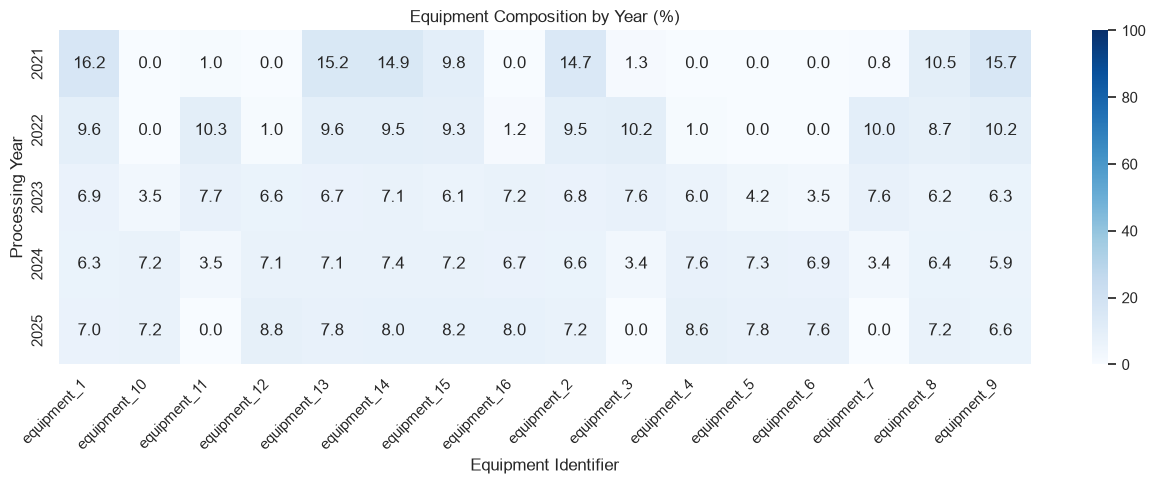

In [14]:

# STEP 2.4.10 - Equipment mix by year

analysis_df["run_year"] = (
    analysis_df["runstart"].dt.year
)

year_equipment_counts = pd.crosstab(
    analysis_df["run_year"],
    analysis_df["equipment"]
)

# Convert to within-year percentages
year_equipment_pct = (
    year_equipment_counts
    .div(year_equipment_counts.sum(axis=1), axis=0)
    * 100
)

display(year_equipment_pct.round(2))

plt.figure(figsize=(13, 5))

sns.heatmap(
    year_equipment_pct,
    cmap="Blues",
    annot=True,
    fmt=".1f",
    vmin=0,
    vmax=100
)

plt.title("Equipment Composition by Year (%)")
plt.xlabel("Equipment Identifier")
plt.ylabel("Processing Year")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()


## 9. Process Timestamp Consistency

Validate processing timestamp ordering and examine
recorded run intervals.

Do not assume that runend - runstart represents
the physical deposition duration.

In [15]:

# STEP 2.4.11 - Timestamp consistency checks

analysis_df["run_interval_min"] = (
    analysis_df["runend"]
    - analysis_df["runstart"]
).dt.total_seconds() / 60

negative_intervals = (
    analysis_df["run_interval_min"] < 0
).sum()

zero_intervals = (
    analysis_df["run_interval_min"] == 0
).sum()

print("Negative run intervals:", negative_intervals)
print("Zero run intervals:", zero_intervals)

print("\nRun interval summary (minutes):")
display(
    analysis_df["run_interval_min"]
    .describe(percentiles=[0.01, 0.5, 0.99])
    .round(2)
)

print("\nRepeated run-end timestamps:")
print(
    analysis_df["runend"].duplicated().sum()
)

Negative run intervals: 0
Zero run intervals: 0

Run interval summary (minutes):


count    5208.00
mean       48.34
std        42.45
min         1.45
1%          4.50
50%        33.53
99%       189.26
max       209.57
Name: run_interval_min, dtype: float64


Repeated run-end timestamps:
1181



## 10. Preliminary ML Evaluation Strategy

Investigate a chronological split of manufacturing records.

Check whether production lots appear across
the training and testing periods.

This is a diagnostic exercise only.

Final splitting, preprocessing and feature
selection will be performed in Step 2.7.

In [16]:

# STEP 2.4.12 - Preliminary chronological split

ordered_df = (
    analysis_df
    .sort_values(["runstart", "wafer_id"])
    .reset_index(drop=True)
)

split_index = int(len(ordered_df) * 0.80)

earlier_records = ordered_df.iloc[:split_index].copy()
later_records = ordered_df.iloc[split_index:].copy()

earlier_lots = set(earlier_records["lot"])
later_lots = set(later_records["lot"])

shared_lots = earlier_lots.intersection(later_lots)

print("Earlier records:", len(earlier_records))
print("Later records:", len(later_records))

print("\nLast earlier timestamp:",
      earlier_records["runstart"].max())

print("First later timestamp:",
      later_records["runstart"].min())

print("\nUnique earlier lots:", len(earlier_lots))
print("Unique later lots:", len(later_lots))

print("Lots appearing in both partitions:",
      len(shared_lots))

print("\nShared equipment identifiers:",
      len(
          set(earlier_records["equipment"])
          & set(later_records["equipment"])
      ))

Earlier records: 4166
Later records: 1042

Last earlier timestamp: 2024-07-31 13:58:35
First later timestamp: 2024-07-31 17:05:11

Unique earlier lots: 2361
Unique later lots: 590
Lots appearing in both partitions: 0

Shared equipment identifiers: 13



## 11. Key Findings and Interpretation

### Equipment-Level Analysis
- Investigated wafer record distribution across 16
  anonymised equipment identifiers.
- Compared mean film thickness and sheet resistance
  across equipment groups.
- Examined the relationship between equipment and
  machine identifiers.

### Production Lot Analysis
- Identified 2,951 unique production lots.
- Observed between one and three wafer records per
  lot in the released dataset.
- Identified 1,582 lots associated with multiple
  equipment identifiers.
- Recognised the importance of lot-aware model evaluation.

### Temporal Analysis
- Examined records spanning July 2021 to May 2025.
- Analysed monthly wafer record counts.
- Investigated changes in mean thickness and
  sheet resistance over time.
- Compared equipment representation across years.

### Data Integrity
- Inspected processing timestamp ordering.
- Calculated recorded run intervals.
- Examined repeated completion timestamps.

### ML Evaluation Implications
- A random row split may not adequately represent
  future manufacturing performance.
- Chronological splitting should be considered.
- Production-lot overlap must be investigated.
- Equipment-specific performance should be assessed.
- Preprocessing must be fitted on training data only.

### Limitations
- Equipment and machine identifiers are anonymised.
- The data may not represent all factory production.
- Observed differences do not establish causal effects.
- Production recipes and engineering thresholds are
  not fully documented.
- The final train/test split is not yet defined.

### Conclusion

This analysis supports the need for equipment-aware
monitoring and a carefully designed evaluation
strategy for STRATUM's virtual metrology models.

No model training or final feature selection has
been performed in this notebook.